In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import brentq

lambda_2 = -1.5107114281899214
time when TV = 0.01: 2.897990636021128
ln(100)/|lambda_2| = 3.048345368980121


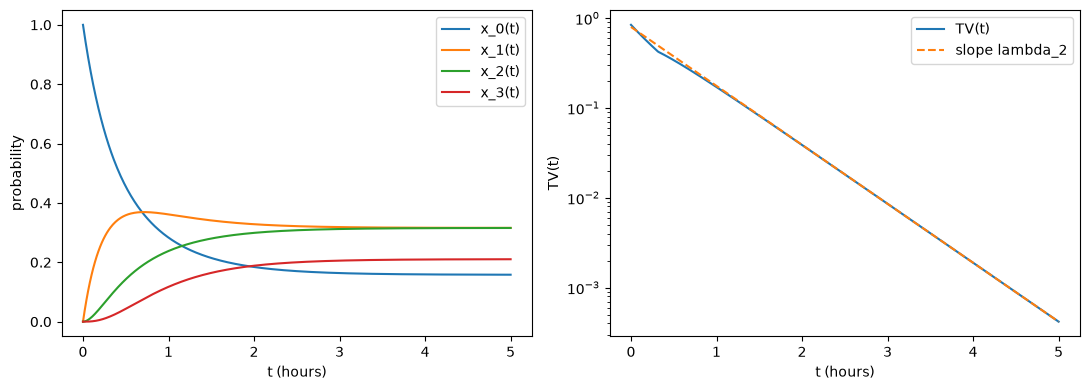

In [3]:
Q = np.array([[-2, 2, 0, 0],
              [1, -3, 2, 0],
              [0, 2, -4, 2],
              [0, 0, 3, -3]])
pi = np.array([3, 6, 6, 4]) / 19
x0 = np.array([1, 0, 0, 0])
lam2 = np.sort(np.linalg.eigvals(Q).real)[-2]


def x(t):
    return x0 @ expm(t * Q)


def tv(t):
    return 0.5 * np.abs(x(t) - pi).sum()


ts = np.linspace(0, 5, 501)
xs = np.array([x(t) for t in ts])
tvs = np.array([tv(t) for t in ts])

t_star = brentq(lambda t: tv(t) - 0.01, 0, 5)
print("lambda_2 =", lam2)
print("time when TV = 0.01:", t_star)
print("ln(100)/|lambda_2| =", np.log(100) / abs(lam2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for i in range(4):
    ax[0].plot(ts, xs[:, i], label=f"x_{i}(t)")
ax[0].set_xlabel("t (hours)")
ax[0].set_ylabel("probability")
ax[0].legend()

ax[1].semilogy(ts, tvs, label="TV(t)")
ax[1].semilogy(ts, tvs[-1] * np.exp(lam2 * (ts - 5)), "--", label="slope lambda_2")
ax[1].set_xlabel("t (hours)")
ax[1].set_ylabel("TV(t)")
ax[1].legend()

plt.tight_layout()
plt.savefig("problem3c.png", dpi=150)
plt.show()